# 冠军模型总对比：谁是当前最佳模型？

本 Notebook 不再训练新模型，而是使用完全相同的757个held-out test cases，对当前第一梯队进行统一总结：

- Gradient Boosting residual
- Optimised FNN
- Optimised Weighted KNN
- Optimised Random Forest

并与两条物理baseline比较：velocity persistence与spatial mean flow。

评价不只看RMSE，而是同时检查：72 h median error、72 h RMSE、median ITE、最差10% RMSE、逐lead-time误差和相对baseline的forecast skill。

> 这是已完成实验的总结性比较。由于test set已经在模型开发过程中被多次查看，数值应视作项目内的描述性最终比较，而不是全新的完全盲测。

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython import get_ipython
from IPython.display import display, Markdown

ip=get_ipython()
if ip is not None: ip.run_line_magic('matplotlib','inline')
PROJECT_ROOT=next((p for p in [Path.cwd(),*Path.cwd().parents] if (p/'output'/'rq1'/'zh').exists()),None)
if PROJECT_ROOT is None: raise FileNotFoundError('找不到output/rq1/zh。')
OUTPUT=PROJECT_ROOT/'output'/'rq1'/'zh'; PROCESSED=PROJECT_ROOT/'data'/'processed'
plt.style.use('seaborn-v0_8-whitegrid'); plt.rcParams['font.sans-serif']=['PingFang SC','Arial Unicode MS','DejaVu Sans']; plt.rcParams['axes.unicode_minus']=False

MODELS={
 'Boosting residual':('boosting_residual_lead_metrics.csv','boosting_residual_test_case_metrics.csv'),
 'Optimised FNN':('optimised_fnn_lead_metrics.csv','optimised_fnn_test_case_metrics.csv'),
 'Optimised KNN':('optimised_knn_lead_metrics.csv','optimised_knn_test_case_metrics.csv'),
 'Optimised Random Forest':('optimised_random_forest_lead_metrics.csv','optimised_random_forest_test_case_metrics.csv'),
}
BASELINES={
 'Velocity persistence':('velocity_persistence_lead_metrics.csv','velocity_persistence_test_case_metrics.csv'),
 'Spatial mean flow':('spatial_mean_flow_lead_metrics.csv','spatial_mean_flow_test_case_metrics.csv'),
}
COLORS={'Boosting residual':'#d81b60','Optimised FNN':'#7b1fa2','Optimised KNN':'#009e73','Optimised Random Forest':'#0072b2','Velocity persistence':'#666666','Spatial mean flow':'#a0a7ad'}
origins=pd.read_parquet(PROCESSED/'forecast_origins.parquet',columns=['forecast_case_id','ID','partition'])
test_map=origins[origins.partition.eq('test')][['forecast_case_id','ID']].rename(columns={'ID':'drifter_id'})
print('结果目录：',OUTPUT)

结果目录： /Users/roger/Documents/data3001-project/output/rq1/zh


## 1. 统一读取逐lead-time和逐case结果

In [2]:
def load_lead(filename,label,kind):
    d=pd.read_csv(OUTPUT/filename)[['lead_time_hours','median_error_km','rmse_km']].copy(); d['model']=label; d['kind']=kind; return d
def load_case(filename,label,kind):
    d=pd.read_csv(OUTPUT/filename).copy()
    if 'error_72h_km' not in d: d=d.rename(columns={'final_72h_error_km':'error_72h_km'})
    if 'ite_km_h' not in d: d=d.rename(columns={'integrated_trajectory_error_km_h':'ite_km_h'})
    if 'drifter_id' not in d: d=d.merge(test_map,on='forecast_case_id',how='left')
    return d[['forecast_case_id','drifter_id','error_72h_km','ite_km_h']].assign(model=label,kind=kind)

lead=pd.concat([load_lead(f[0],name,'learned') for name,f in MODELS.items()]+[load_lead(f[0],name,'baseline') for name,f in BASELINES.items()],ignore_index=True)
cases=pd.concat([load_case(f[1],name,'learned') for name,f in MODELS.items()]+[load_case(f[1],name,'baseline') for name,f in BASELINES.items()],ignore_index=True)
assert lead.groupby('model').size().eq(72).all() and cases.groupby('model').size().eq(757).all()
print('lead rows:',len(lead),'case rows:',len(cases))

lead rows: 432 case rows: 4542


## 2. 全指标leaderboard

In [3]:
rows=[]
for model,g in cases.groupby('model',sort=False):
    e=g.error_72h_km.to_numpy(); q=np.quantile(e,.9)
    rows.append({'model':model,'kind':g.kind.iloc[0],'median_72h_km':np.median(e),'rmse_72h_km':np.sqrt(np.mean(e**2)),'median_ite_km_h':np.median(g.ite_km_h),'worst10_rmse_72h_km':np.sqrt(np.mean(e[e>=q]**2)),'p90_72h_km':q})
leaderboard=pd.DataFrame(rows).sort_values('rmse_72h_km')
display(leaderboard.round(2))

learned=leaderboard[leaderboard.kind.eq('learned')].copy()
metrics=['median_72h_km','rmse_72h_km','median_ite_km_h','worst10_rmse_72h_km']
for m in metrics: learned[f'rank_{m}']=learned[m].rank(method='min')
learned['balanced_rank']=learned[[f'rank_{m}' for m in metrics]].mean(axis=1)
learned=learned.sort_values(['balanced_rank','rmse_72h_km'])
display(Markdown('### 四项指标等权排名（仅用于总结，不替代各指标含义）')); display(learned[['model',*metrics,'balanced_rank']].round(2))

,model,kind,median_72h_km,rmse_72h_km,median_ite_km_h,worst10_rmse_72h_km,p90_72h_km
0,Boosting residual,learned,42.07,60.77,1412.49,130.15,97.79
1,Optimised FNN,learned,41.34,61.69,1403.16,134.60,97.44
3,Optimised Random Forest,learned,41.89,62.17,1414.58,136.60,97.54
2,Optimised KNN,learned,41.13,63.71,1433.11,142.08,101.59
5,Spatial mean flow,baseline,56.42,80.98,2201.71,170.54,133.26
4,Velocity persistence,baseline,61.35,90.10,1962.45,194.34,141.48


### 四项指标等权排名（仅用于总结，不替代各指标含义）

,model,median_72h_km,rmse_72h_km,median_ite_km_h,worst10_rmse_72h_km,balanced_rank
1,Optimised FNN,41.34,61.69,1403.16,134.60,1.75
0,Boosting residual,42.07,60.77,1412.49,130.15,2.00
3,Optimised Random Forest,41.89,62.17,1414.58,136.60,3.00
2,Optimised KNN,41.13,63.71,1433.11,142.08,3.25


## 3. 误差随lead time增长：所有模型与baselines

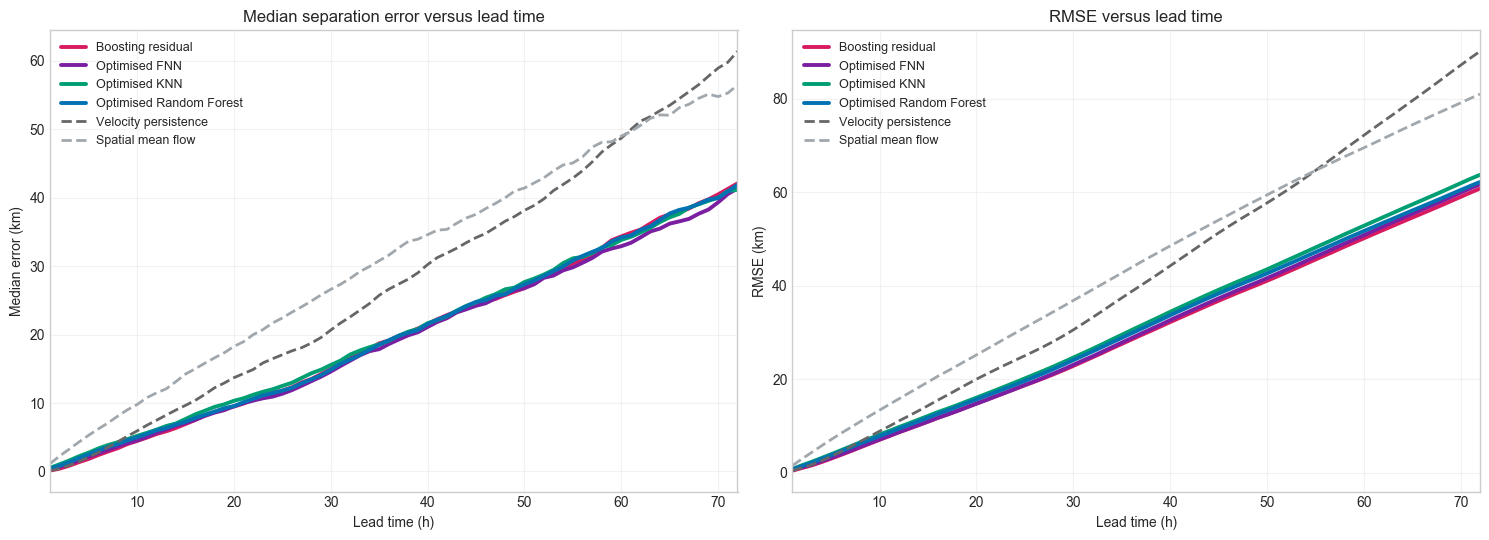

In [4]:
fig,axes=plt.subplots(1,2,figsize=(15,5.5))
for model,g in lead.groupby('model',sort=False):
    ls='--' if g.kind.iloc[0]=='baseline' else '-'; lw=2.8 if g.kind.iloc[0]=='learned' else 2
    axes[0].plot(g.lead_time_hours,g.median_error_km,label=model,color=COLORS[model],ls=ls,lw=lw)
    axes[1].plot(g.lead_time_hours,g.rmse_km,label=model,color=COLORS[model],ls=ls,lw=lw)
axes[0].set(title='Median separation error versus lead time',xlabel='Lead time (h)',ylabel='Median error (km)',xlim=(1,72))
axes[1].set(title='RMSE versus lead time',xlabel='Lead time (h)',ylabel='RMSE (km)',xlim=(1,72))
for ax in axes: ax.legend(frameon=False,fontsize=9); ax.grid(alpha=.25)
plt.tight_layout(); fig.savefig(OUTPUT/'champion_models_lead_time_comparison.png',dpi=200,bbox_inches='tight'); plt.show()

## 4. 72小时四项指标：谁在哪一项获胜？

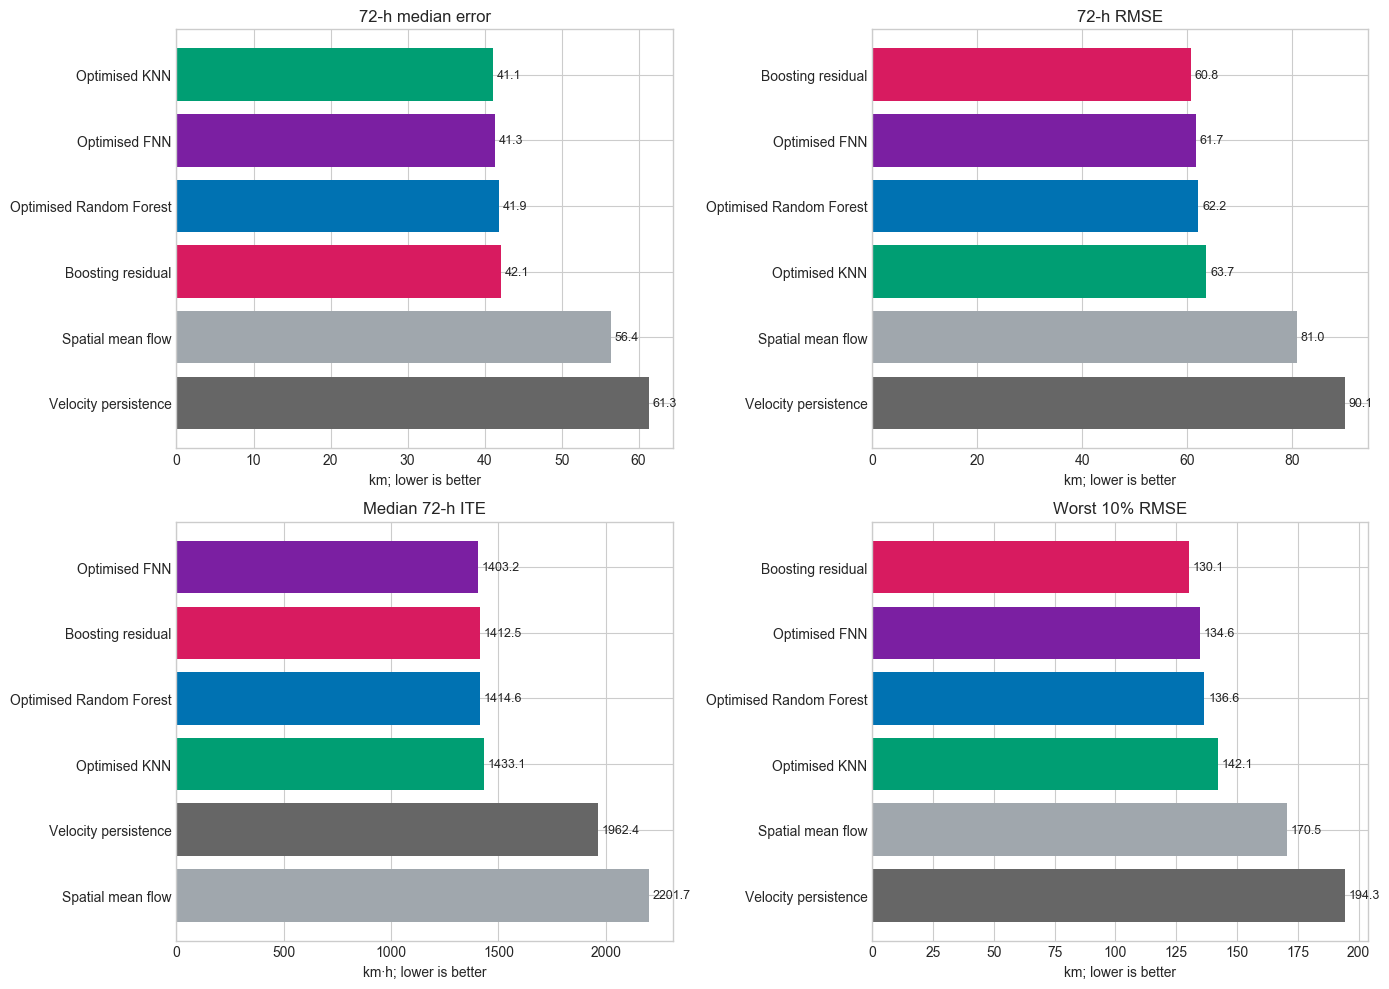

In [5]:
fig,axes=plt.subplots(2,2,figsize=(14,10)); panel_metrics=[('median_72h_km','72-h median error','km'),('rmse_72h_km','72-h RMSE','km'),('median_ite_km_h','Median 72-h ITE','km·h'),('worst10_rmse_72h_km','Worst 10% RMSE','km')]
for ax,(metric,title,unit) in zip(axes.flat,panel_metrics):
    q=leaderboard.sort_values(metric,ascending=False); ax.barh(q.model,q[metric],color=[COLORS[x] for x in q.model]); ax.set_title(title); ax.set_xlabel(f'{unit}; lower is better')
    for i,v in enumerate(q[metric]): ax.text(v+.008*q[metric].max(),i,f'{v:.1f}',va='center',fontsize=9)
plt.tight_layout(); fig.savefig(OUTPUT/'champion_models_four_metrics.png',dpi=200,bbox_inches='tight'); plt.show()

## 5. 每个优秀模型分别与两条baseline对比

每个面板只放一个learned model和两条baseline，使改善幅度更加直观。

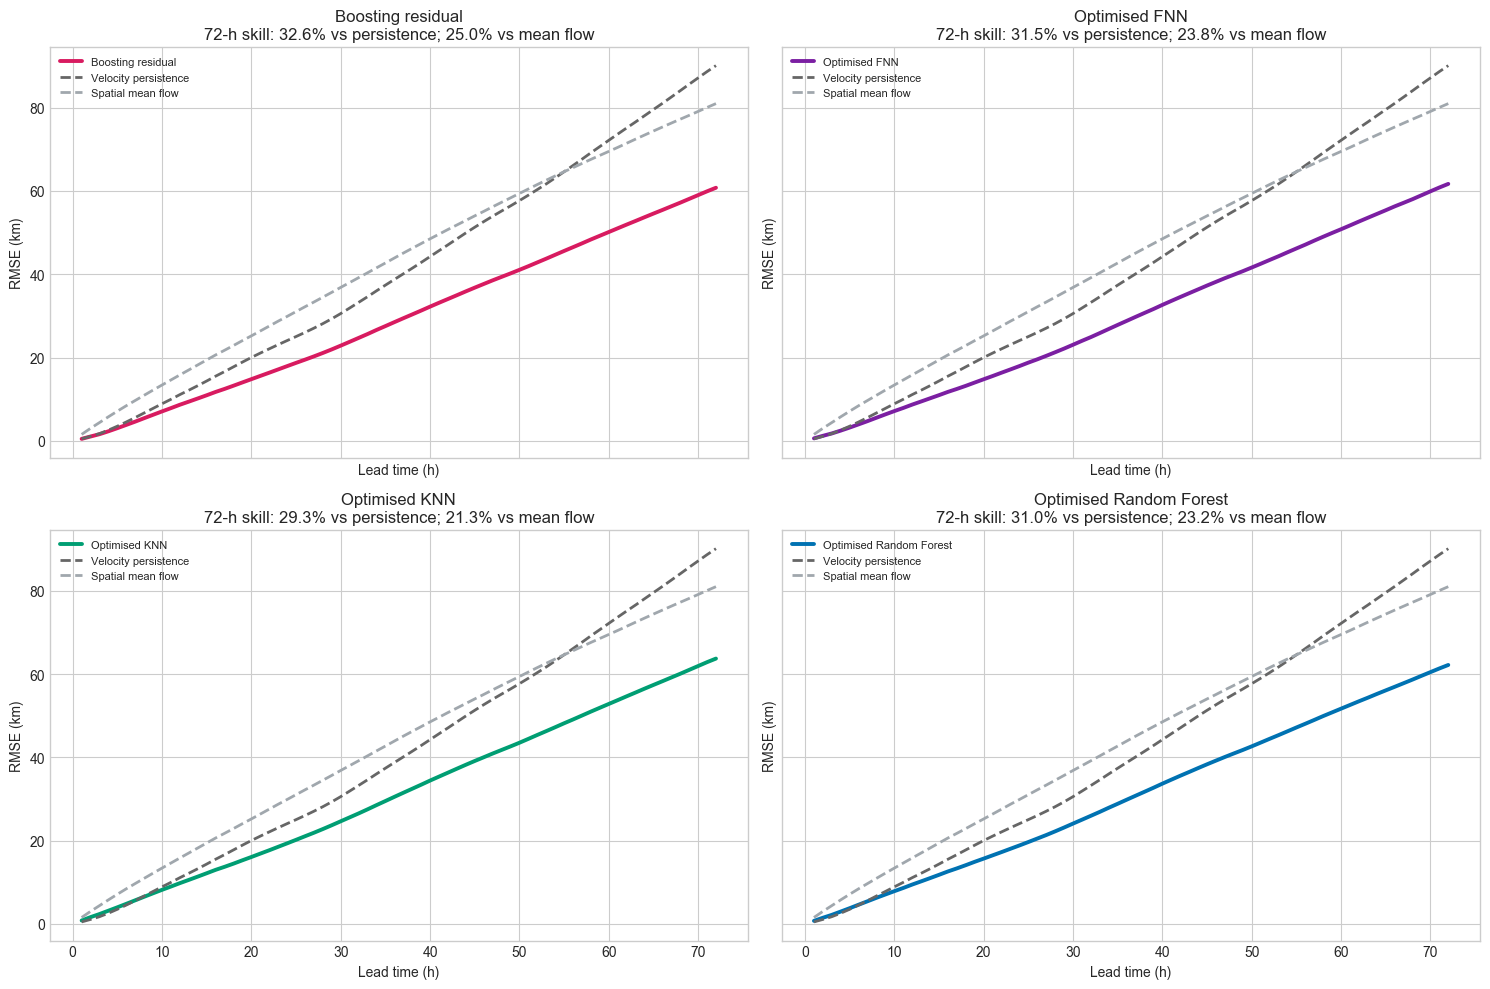

In [6]:
fig,axes=plt.subplots(2,2,figsize=(15,10),sharex=True,sharey=True)
for ax,model in zip(axes.flat,MODELS):
    for name in [model,*BASELINES]:
        g=lead[lead.model.eq(name)]; ax.plot(g.lead_time_hours,g.rmse_km,color=COLORS[name],lw=2.8 if name==model else 2,ls='-' if name==model else '--',label=name)
    m72=float(lead[(lead.model.eq(model))&lead.lead_time_hours.eq(72)].rmse_km.iloc[0]); p72=float(lead[(lead.model.eq('Velocity persistence'))&lead.lead_time_hours.eq(72)].rmse_km.iloc[0]); f72=float(lead[(lead.model.eq('Spatial mean flow'))&lead.lead_time_hours.eq(72)].rmse_km.iloc[0])
    ax.set_title(f'{model}\n72-h skill: {100*(1-m72/p72):.1f}% vs persistence; {100*(1-m72/f72):.1f}% vs mean flow'); ax.set_xlabel('Lead time (h)'); ax.set_ylabel('RMSE (km)'); ax.legend(frameon=False,fontsize=8)
plt.tight_layout(); fig.savefig(OUTPUT/'champion_models_individual_vs_baselines.png',dpi=200,bbox_inches='tight'); plt.show()

## 6. Forecast skill相对baseline如何随lead time变化？

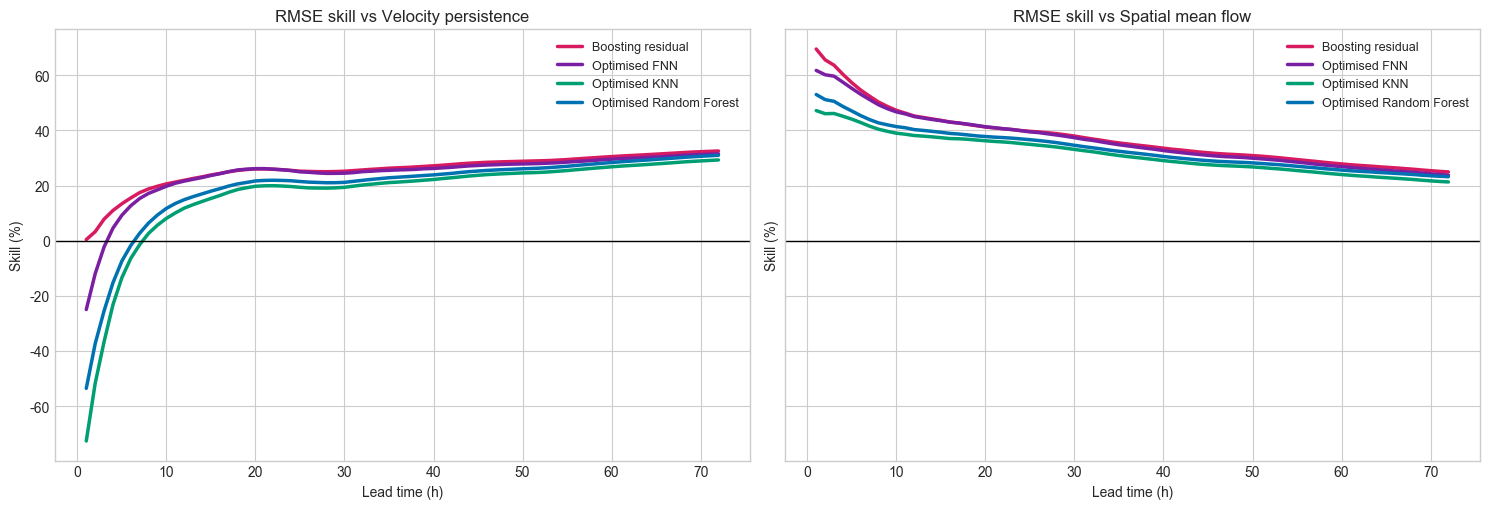

baseline,Spatial mean flow,Velocity persistence
model,,
Boosting residual,24.96,32.56
Optimised FNN,23.81,31.53
Optimised KNN,21.33,29.29
Optimised Random Forest,23.22,31.00


In [7]:
skills=[]
for model in MODELS:
    m=lead[lead.model.eq(model)].set_index('lead_time_hours')
    for base in BASELINES:
        b=lead[lead.model.eq(base)].set_index('lead_time_hours')
        for h in m.index: skills.append({'model':model,'baseline':base,'lead_time_hours':h,'skill_pct':100*(1-m.loc[h,'rmse_km']/b.loc[h,'rmse_km'])})
skills=pd.DataFrame(skills)
fig,axes=plt.subplots(1,2,figsize=(15,5.2),sharey=True)
for ax,base in zip(axes,BASELINES):
    for model,g in skills[skills.baseline.eq(base)].groupby('model',sort=False): ax.plot(g.lead_time_hours,g.skill_pct,label=model,color=COLORS[model],lw=2.5)
    ax.axhline(0,color='black',lw=1); ax.set(title=f'RMSE skill vs {base}',xlabel='Lead time (h)',ylabel='Skill (%)'); ax.legend(frameon=False,fontsize=9)
plt.tight_layout(); fig.savefig(OUTPUT/'champion_models_forecast_skill_curves.png',dpi=200,bbox_inches='tight'); plt.show()

skill72=skills[skills.lead_time_hours.eq(72)].pivot(index='model',columns='baseline',values='skill_pct').loc[list(MODELS)]
display(skill72.round(2))

## 7. 按drifter配对bootstrap：相对baseline的RMSE改善是否稳定？

In [8]:
def bootstrap_contrast(model,baseline,B=5000):
    a=cases[cases.model.eq(model)][['forecast_case_id','drifter_id','error_72h_km']].rename(columns={'error_72h_km':'model_error'})
    b=cases[cases.model.eq(baseline)][['forecast_case_id','error_72h_km']].rename(columns={'error_72h_km':'base_error'})
    d=a.merge(b,on='forecast_case_id'); groups={k:g for k,g in d.groupby('drifter_id')}; ids=np.array(list(groups)); rng=np.random.default_rng(2026); diffs=[]
    for _ in range(B):
        parts=[groups[i] for i in rng.choice(ids,len(ids),replace=True)]; x=np.concatenate([p.model_error for p in parts]); y=np.concatenate([p.base_error for p in parts]); diffs.append(np.sqrt(np.mean(x*x))-np.sqrt(np.mean(y*y)))
    point=np.sqrt(np.mean(d.model_error**2))-np.sqrt(np.mean(d.base_error**2)); lo,hi=np.quantile(diffs,[.025,.975])
    return {'model':model,'baseline':baseline,'rmse_difference_km':point,'ci_2.5_km':lo,'ci_97.5_km':hi,'improvement_supported':hi<0}

bootstrap=pd.DataFrame([bootstrap_contrast(m,b) for m in MODELS for b in BASELINES]); display(bootstrap.round(2))

,model,baseline,rmse_difference_km,ci_2.5_km,ci_97.5_km,improvement_supported
0,Boosting residual,Velocity persistence,-29.33,-34.07,-24.66,True
1,Boosting residual,Spatial mean flow,-20.21,-24.73,-15.42,True
2,Optimised FNN,Velocity persistence,-28.41,-33.11,-23.68,True
3,Optimised FNN,Spatial mean flow,-19.28,-23.92,-14.16,True
4,Optimised KNN,Velocity persistence,-26.39,-31.27,-21.54,True
5,Optimised KNN,Spatial mean flow,-17.27,-21.83,-12.11,True
6,Optimised Random Forest,Velocity persistence,-27.93,-32.61,-23.25,True
7,Optimised Random Forest,Spatial mean flow,-18.81,-23.48,-13.62,True


## 8. 最终判断：哪个最好？

In [9]:
winner_median=leaderboard.loc[leaderboard.median_72h_km.idxmin(),'model']; winner_rmse=leaderboard.loc[leaderboard.rmse_72h_km.idxmin(),'model']; winner_ite=leaderboard.loc[leaderboard.median_ite_km_h.idxmin(),'model']; winner_tail=leaderboard.loc[leaderboard.worst10_rmse_72h_km.idxmin(),'model']; balanced=learned.iloc[0].model
display(Markdown(f"""### 结论

- **典型72小时case（median）最佳：{winner_median}**。
- **总体平方误差（RMSE）最佳：{winner_rmse}**。
- **整条轨迹累计误差（ITE）最佳：{winner_ite}**。
- **极端失败控制最佳：{winner_tail}**。
- 四项指标等权排名下，最均衡的模型是 **{balanced}**。

因此不能把“最佳模型”压缩成一个不带条件的名字：

1. 若业务最怕搜索区域严重偏离或漏掉目标，应优先 **Boosting residual**，因为RMSE和最差10%误差最低；
2. 若强调72小时整条轨迹的综合稳定性，应优先 **Optimised FNN**，因为ITE最低且各项都处于第一梯队；
3. 若只描述典型case最终位置，应报告 **Optimised KNN** 的最低median，但同时说明其尾部误差更大；
4. Random Forest是稳定参照，但目前没有单项冠军。
"""))

### 结论

- **典型72小时case（median）最佳：Optimised KNN**。
- **总体平方误差（RMSE）最佳：Boosting residual**。
- **整条轨迹累计误差（ITE）最佳：Optimised FNN**。
- **极端失败控制最佳：Boosting residual**。
- 四项指标等权排名下，最均衡的模型是 **Optimised FNN**。

因此不能把“最佳模型”压缩成一个不带条件的名字：

1. 若业务最怕搜索区域严重偏离或漏掉目标，应优先 **Boosting residual**，因为RMSE和最差10%误差最低；
2. 若强调72小时整条轨迹的综合稳定性，应优先 **Optimised FNN**，因为ITE最低且各项都处于第一梯队；
3. 若只描述典型case最终位置，应报告 **Optimised KNN** 的最低median，但同时说明其尾部误差更大；
4. Random Forest是稳定参照，但目前没有单项冠军。


## 9. 保存汇总表和图片

In [10]:
leaderboard.to_csv(OUTPUT/'champion_models_leaderboard.csv',index=False); learned.to_csv(OUTPUT/'champion_models_balanced_ranking.csv',index=False); skills.to_csv(OUTPUT/'champion_models_forecast_skill_by_lead.csv',index=False); skill72.to_csv(OUTPUT/'champion_models_72h_skill_vs_baselines.csv'); bootstrap.to_csv(OUTPUT/'champion_models_bootstrap_vs_baselines.csv',index=False)
print('已保存综合表格与图片到：',OUTPUT)

已保存综合表格与图片到： /Users/roger/Documents/data3001-project/output/rq1/zh
